In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
data = pd.read_csv("../data/scoring.csv")
data.head()

,age,income,education,work,car,default
0,27,32,0,0,1,0
1,26,50,1,0,0,0
2,35,20,0,1,0,0
3,35,80,1,1,0,0
4,24,27,0,0,0,0


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 180816 entries, 0 to 180815
Data columns (total 6 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   age        180816 non-null  int64
 1   income     180816 non-null  int64
 2   education  180816 non-null  int64
 3   work       180816 non-null  int64
 4   car        180816 non-null  int64
 5   default    180816 non-null  int64
dtypes: int64(6)
memory usage: 8.3 MB


In [5]:
data["default"].value_counts()

default
0    159982
1     20834
Name: count, dtype: int64

In [6]:
defaults = data[data["default"] == 1]
defaults.head()

,age,income,education,work,car,default
7,55,8,0,0,1,1
12,21,30,0,0,0,1
22,58,32,0,0,1,1
24,40,37,1,0,1,1
26,61,8,0,0,0,1


In [7]:
defaults["work"].value_counts()

work
0    18405
1     2429
Name: count, dtype: int64

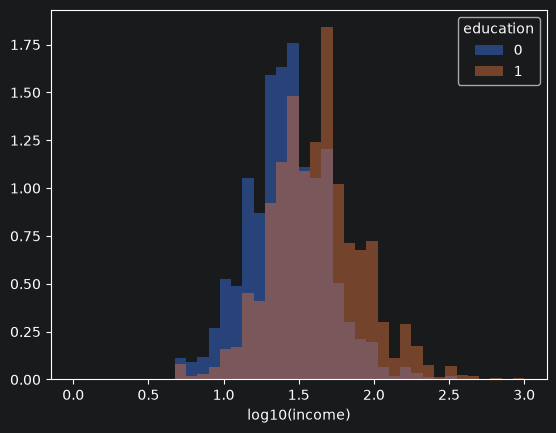

In [8]:
levels = data["education"].unique()
bins = np.histogram_bin_edges(np.log10(data["income"].clip(lower=1)), bins=40)

fig, ax = plt.subplots()
for lvl in levels:
    ax.hist(np.log10(data.loc[data["education"] == lvl, "income"].clip(lower=1)),
            bins=bins, alpha=0.5, density=True, label=str(lvl))
ax.set(xlabel="log10(income)")
ax.legend(title="education")
plt.show()

In [9]:
data.nunique()

age           52
income       303
education      2
work           2
car            2
default        2
dtype: int64

In [14]:
len(data.drop_duplicates()), len(data)

(26882, 180816)